In [2]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

df = pd.read_csv('sales_electroprima4.csv')
df.head()
df.shape

(2200, 14)

In [3]:
print(df['customer_age'].isna().sum())
print(df['satisfaction_rating'].isna().sum())

132
176


(array([0.03132621, 0.01766042, 0.02354722, 0.04562274, 0.03195694,
        0.03889496, 0.0542427 , 0.03637205, 0.03111597, 0.03216719,
        0.03426962, 0.01639896, 0.01534774, 0.01282483, 0.00546632,
        0.00399462, 0.00231267, 0.00042049, 0.00021024, 0.00063073]),
 array([18. , 20.3, 22.6, 24.9, 27.2, 29.5, 31.8, 34.1, 36.4, 38.7, 41. ,
        43.3, 45.6, 47.9, 50.2, 52.5, 54.8, 57.1, 59.4, 61.7, 64. ]),
 <BarContainer object of 20 artists>)

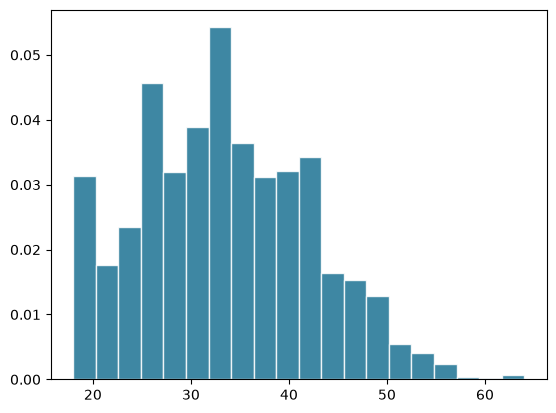

In [4]:
age = df['customer_age'].dropna()
mu, sigma = age.mean(), age.std()

plt.hist(age, bins=20, density=True,
        color='#1C7293', edgecolor='white', alpha=0.85)

In [ ]:
mu = df['customer_age'].mean()
sigma = df['customer_age'].std()

for age_check in [60, 20, 45]:
    z = (age_check - mu) / sigma
    print(f'Age {age_check} years -> z = {z:.2f}')

Age 60 years -> z = 3.05
Age 20 years -> z = -1.54
Age 45 years -> z = 1.33


In [6]:
print('Skewness of customer_age:', df['customer_age'].skew())
print('Mean  :', df['customer_age'].mean())
print('Median:', df['customer_age'].median())

Skewness of customer_age: 0.26148177716388565
Mean  : 33.41392649903288
Median: 33.0


In [7]:
df['customer_age_imputed'] = df['customer_age'].fillna(
    df['customer_age'].median()
)

print('NaN count before:', df['customer_age'].isna().sum())
print('NaN count after :', df['customer_age_imputed'].isna().sum())

NaN count before: 132
NaN count after : 0


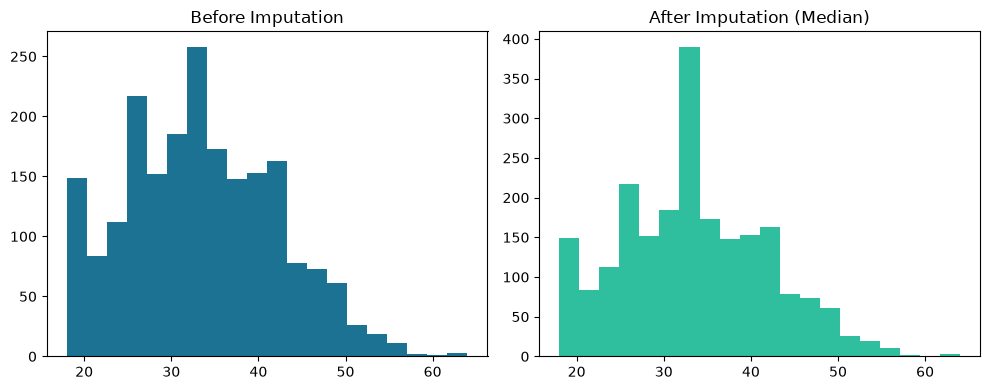

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(df['customer_age'].dropna(), bins=20, color='#1C7293')
axes[0].set_title('Before Imputation')

axes[1].hist(df['customer_age_imputed'], bins=20, color='#2FBF9F')
axes[1].set_title('After Imputation (Median)')

plt.tight_layout()
plt.show()

In [9]:
print('Skewness of satisfaction_rating:', df['satisfaction_rating'].skew())
print('Mean  :', df['satisfaction_rating'].mean())
print('Median:', df['satisfaction_rating'].median())

df['satisfaction_mean_imputed'] = df['satisfaction_rating'].fillna(df['satisfaction_rating'].mean())
df['satisfaction_median_imputed'] = df['satisfaction_rating'].fillna(df['satisfaction_rating'].median())

print('NaN count sebelum imputasi:', df['satisfaction_rating'].isna().sum())
print('NaN count setelah Mean Imputation:', df['satisfaction_mean_imputed'].isna().sum())
print('NaN count setelah Median Imputation:', df['satisfaction_median_imputed'].isna().sum())

print('\n--- Perbandingan Hasil ---')
print('Mean dari kolom satisfaction_mean_imputed   :', df['satisfaction_mean_imputed'].mean())
print('Median dari kolom satisfaction_mean_imputed :', df['satisfaction_mean_imputed'].median())
print('Mean dari kolom satisfaction_median_imputed :', df['satisfaction_median_imputed'].mean())
print('Median dari kolom satisfaction_median_imputed:', df['satisfaction_median_imputed'].median())

Skewness of satisfaction_rating: -1.0116524441351287
Mean  : 3.986166007905138
Median: 4.0
NaN count sebelum imputasi: 176
NaN count setelah Mean Imputation: 0
NaN count setelah Median Imputation: 0

--- Perbandingan Hasil ---
Mean dari kolom satisfaction_mean_imputed   : 3.986166007905138
Median dari kolom satisfaction_mean_imputed : 4.0
Mean dari kolom satisfaction_median_imputed : 3.9872727272727273
Median dari kolom satisfaction_median_imputed: 4.0


In [10]:
mu_sat = df['satisfaction_rating'].mean()
sigma_sat = df['satisfaction_rating'].std()

for rating_check in [1, 5]:
    z = (rating_check - mu_sat) / sigma_sat
    print(f'Satisfaction Rating {rating_check} -> z = {z:.2f} (Absolute Z: {abs(z):.2f})')

Satisfaction Rating 1 -> z = -3.01 (Absolute Z: 3.01)
Satisfaction Rating 5 -> z = 1.02 (Absolute Z: 1.02)


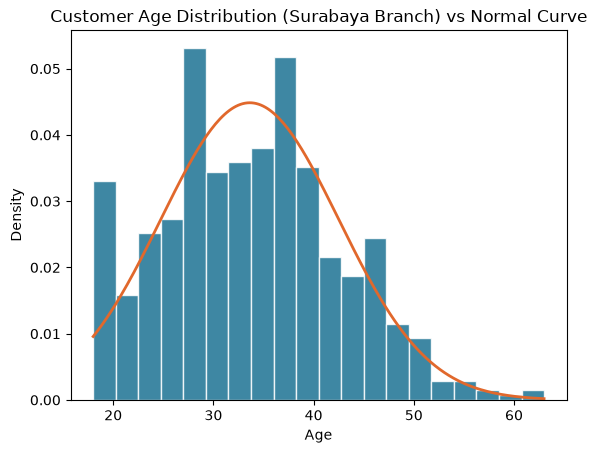

In [11]:
df_surabaya = df[df['branch'] == 'Surabaya']

age_sby = df_surabaya['customer_age'].dropna()
mu_sby, sigma_sby = age_sby.mean(), age_sby.std()

plt.hist(age_sby, bins=20, density=True,
        color='#1C7293', edgecolor='white', alpha=0.85)

x_sby = np.linspace(age_sby.min(), age_sby.max(), 200)
plt.plot(x_sby, stats.norm.pdf(x_sby, mu_sby, sigma_sby), color='#E1682C', linewidth=2)

plt.title('Customer Age Distribution (Surabaya Branch) vs Normal Curve')
plt.xlabel('Age'); plt.ylabel('Density')
plt.show()